In [1]:
%load_ext autoreload
%autoreload 2

# Fine-tuning on Pre-trained Model for Transcriptomic Enhancement
In this tutorial, we demonstrate how to fine-tune a pre-trained model for transcriptomic enhancement. We use the CITE BMMC S1 dataset which contains both RNA and ADT measurements.

We summarize the fine-tuning pipeline in the following steps, which can be used as general recipe for fine-tuning on transcriptomic enhancement task and beyond:

    1. Specify hyper-parameter setup for transcriptomic enhancement
    2. Load and pre-process data
    3. Load the pre-trained scPMMI model
    4. fine-tune scPMMI with task-specific objectives
    5. Evaluate fine-tuned scPMMI

In [2]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings('ignore')

import os
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import muon as mu
import scanpy as sc
import muon as mu
import random
from tqdm import tqdm
from typing import Tuple
from scipy.sparse import issparse
import swanlab
import matplotlib.pyplot as plt

import torch
from torch import optim, Tensor, nn
from torch.utils.data import DataLoader, Dataset
from torch.amp.autocast_mode import autocast
from transformers.optimization import get_scheduler

from scpmmi.utils.unify import align_to_common_genes, align_to_common_proteins
from scpmmi.tokenizer.vocab import Vocab
from scpmmi.models.scPMMI import scPMMI
from scpmmi.loss import ContrastiveLoss
from scpmmi.utils.util import set_seed
from scpmmi import logger

## Step 1: Specify her-parameter setup for enhancement task
This section defines the default hyperparameters used for fine-tuning. The values are collected into a single configuration dictionary that is passed to experiment tracking.

In [3]:
hyperparameter_defaults = dict(
    task='multiomic',
    seed=42,
    dataset_name='CITE_BMMC_S1_raw',
    data_path='../data/mdata/rna_adt/CITE_BMMC_S1_raw.h5mu',
    load_model = '../ckpt/ckpt_protra',
    gene_vocab='../config_file/default_gene_vocab.json',
    protein_vocab='../config_file/default_protein_vocab.json',
    batch_size=64,
    num_workers=4,
    temperature=0.01,
    alpha=1.5,
    n_epochs=10,
    lr=1.5e-4,
    weight_decay=0.05,
)

In [4]:
run = swanlab.init(
    project="scPMMI-fine-tuning",
    experiment_name=f"fine-tuning-{time.strftime('%b%d-%H-%M')}",
    config=hyperparameter_defaults,
    reinit=True,
    mode="offline"
)
config = run.config
set_seed(config.seed)

swanlab: Tracking run with swanlab version 0.6.8

swanlab: Run data will be saved locally in 
/mnt/disk2/zyuan/code/scPMMI/tutorials/swanlog/run-20260125_193026-0x1xatiuyoefiayucm43j

swanlab: Backing up run fine-tuning-Jan25-19-30 locally

swanlab:  ☁️ Run `swanlab sync 
/mnt/disk2/zyuan/code/scPMMI/tutorials/swanlog/run-20260125_193026-0x1xatiuyoefiayucm43j` to sync logs to remote 
server

In [5]:
dataset_name = config.dataset_name
save_path = Path(f"./result/save_multiome_integration_ProTra/dev_{dataset_name}-{time.strftime('%b%d-%H-%M')}/")
save_path.mkdir(parents=True, exist_ok=True)
print(f"save to {save_path}")

save to result/save_multiome_integration_ProTra/dev_CITE_BMMC_S1_raw-Jan25-19-30


## Step 2: Load and pre-process data

### 2.1 load data

In [6]:
if config.data_path.endswith(".h5mu"):
    mdata = mu.read_h5mu(config.data_path)
elif config.data_path.endswith(".h5"):
     mdata = mu.read_10x_h5(config.data_path)
else:
    raise ValueError(f"Unsupported file format: {config.data_path}")

adata_rna = mdata.mod['rna']
adata_adt = mdata.mod['adt'] 
if 'batch' not in adata_rna.obs.columns:
    adata_rna.obs['batch'] = '0'
adata_rna.obs["str_batch"] = adata_rna.obs["batch"].astype(str)
batch_id_labels = adata_rna.obs["str_batch"].astype("category").cat.codes.values
adata_rna.obs["batch_id"] = batch_id_labels
adata_rna

AnnData object with n_obs × n_vars = 11126 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train', 'str_batch', 'batch_id'
    var: 'feature_types', 'gene_id'
    uns: 'dataset_id', 'genome', 'organism'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
    layers: 'counts'

### 2.2 Align genes and proteins to the pre-trained model vocabulary

In [7]:
gene_vocab = Vocab.from_file(config.gene_vocab)
gene_list = gene_vocab.get_token_list()
gene_ids = gene_vocab(gene_list)
adata_rna = align_to_common_genes(adata_rna, gene_list)    

2026-01-25 19:30:27 - scPMMI - INFO - Number of matched genes: 12316


In [8]:
protein_vocab = Vocab.from_file(config.protein_vocab)
protein_list = protein_vocab.get_token_list()
protein_ids = protein_vocab(protein_list)
adata_adt = align_to_common_proteins(adata_adt, protein_list)

2026-01-25 19:30:39 - scPMMI - INFO - Number of matched proteins: 134


## Step 3: Load the pre-trained scPMMI model

In [9]:
device = 'cuda:4'
torch.cuda.set_device(device)
dtype = torch.bfloat16
model_dir = Path(config.load_model)
model_config_file = model_dir / "config.json"
model_ckpt = model_dir / "model.bin"
with open(model_config_file, "r") as f:
    model_config = json.load(f)
model = scPMMI(
    model_config, 
    do_mvc=True,
    use_batch_labels=True,
    num_batch_labels=len(set(batch_id_labels)),
)
if config.load_model is not None:
    try:
        model.load_state_dict(torch.load(model_ckpt))
        logger.info(f"Loading all model params from {model_ckpt}")
    except:
        # only load params that are in the model and match the size
        model_dict = model.state_dict()
        pretrained_dict = torch.load(model_ckpt)
        pretrained_dict = {
            k: v
            for k, v in pretrained_dict.items()
            if k in model_dict and v.shape == model_dict[k].shape
        }
        for k, v in pretrained_dict.items():
            logger.info(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)
model = model.to(device, dtype)

2026-01-25 19:30:41 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.cls_token with shape torch.Size([1, 1, 512])
2026-01-25 19:30:41 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.patch_position_embeddings with shape torch.Size([1, 160, 512])
2026-01-25 19:30:41 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.embedding.weight with shape torch.Size([40957, 512])
2026-01-25 19:30:41 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.norm.weight with shape torch.Size([512])
2026-01-25 19:30:41 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.Wqkv.weight with shape torch.Size([1536, 512])
2026-01-25 19:30:41 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.Wqkv.bias with shape torch.Size([1536])
2026-01-25 19:30:41 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.out_proj.weight with shape torch.Size([512, 512])
2026-01-25 19:30:41 - scPMMI - INFO - Loading params

## Step 4: Fine-tune scPMMI with task-specific objectives

In [10]:
class MultiSeqDataset(Dataset):
    def __init__(
        self,
        adata_rna: sc.AnnData,
        feature_ids_mod1: list,
        adata_adt: sc.AnnData,
        feature_ids_mod2: list,
        batch_id_labels,
    ):
        self.gene_ids = torch.tensor(feature_ids_mod1, dtype=torch.int32)
        self.protein_ids = torch.tensor(feature_ids_mod2, dtype=torch.int32)
        batch_id_labels = torch.tensor(batch_id_labels, dtype=torch.long)
        # ---------------------- Process RNA modality ----------------------
        X_rna = adata_rna.X.toarray() if issparse(adata_rna.X) else adata_rna.X # type: ignore
        X_rna_input = torch.tensor(X_rna, dtype=dtype)
        X_rna_input = torch.log1p(X_rna_input / X_rna_input.sum(1)[:, None] * 1e4)
        gene_ids = self.gene_ids.unsqueeze(0).repeat(X_rna_input.size(0), 1)

        # ---------------------- Process ADT modality ----------------------
        X_adt = adata_adt.X.toarray() if issparse(adata_adt.X) else adata_adt.X # type: ignore

        # Normalize and log-transform
        X_adt_input = np.log1p(X_adt / np.maximum(X_adt.sum(1)[:, None], 1) * 1e3)
        X_adt_input = torch.tensor(X_adt_input)
        protein_ids = self.protein_ids.unsqueeze(0).repeat(X_adt_input.size(0), 1)
        
        # ---------------------- Store both modalities ----------------------
        self.data = {
            "mod1_token_ids": gene_ids,
            "mod1_values": X_rna_input,
            "mod1_values_target": X_rna_input,

            "mod2_token_ids": protein_ids,
            "mod2_values": X_adt_input,
            "mod2_values_target": X_adt_input,
            "batch_id": batch_id_labels
        }

    def __len__(self):
        return self.data["mod1_token_ids"].shape[0]

    def __getitem__(self, idx):
        return {k: v[idx] for k, v in self.data.items()}

In [11]:
dataset = MultiSeqDataset(adata_rna=adata_rna, feature_ids_mod1=gene_ids, 
                            adata_adt=adata_adt, feature_ids_mod2=protein_ids, batch_id_labels=batch_id_labels)

data_loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=False,
                    num_workers=config.num_workers, pin_memory=True)

In [12]:
criterion = ContrastiveLoss(
    temperature=config.temperature, alpha=config.alpha
)
criterion_mse1 = nn.MSELoss()
criterion_mse2 = nn.MSELoss()
optimizer = optim.AdamW( # type: ignore
    model.parameters(), lr=config.lr, weight_decay=config.weight_decay
)
max_train_steps = config.n_epochs * len(data_loader)
num_warmup_steps = int(0.1 * max_train_steps)  # 10% steps for warmup
scheduler = get_scheduler(
    name="cosine",
    optimizer=optimizer,
    num_warmup_steps=num_warmup_steps,
    num_training_steps=max_train_steps,
)

In [13]:
model.train()
global_step = 0
for epoch in range(config.n_epochs):
    loop = tqdm(data_loader, desc=f'Epoch [{epoch}/{config.n_epochs}]',leave=False)
    for step, batch_data in enumerate(loop):
        mod1_token_ids = batch_data["mod1_token_ids"].to(device)
        mod1_values_input = batch_data["mod1_values"].to(device)
        mod1_values_target = batch_data["mod1_values_target"].to(device)

        mod2_token_ids = batch_data["mod2_token_ids"].to(device)
        mod2_values_input = batch_data["mod2_values"].to(device)
        mod2_values_target = batch_data["mod2_values_target"].to(device)
        batch_ids = batch_data["batch_id"].to(device)

        optimizer.zero_grad()
        with autocast(device_type="cuda", dtype=dtype):
            output = model(
                mod1_token_ids, mod1_values_input, 
                mod2_token_ids, mod2_values_input,
                batch_ids,
                MVC=True,
            )
            metric_to_log = {}
            loss_clip = criterion(output['cell_emb_mod1'], output['cell_emb_mod2'])
            loss = loss_clip
            metric_to_log['clip'] = loss_clip.item()


            loss_mse = criterion_mse1(output['mvc_output_mod1'], mod1_values_target.to(output['mvc_output_mod1']))
            loss_bce = criterion_mse2(output['mvc_output_mod2'], mod2_values_target.to(output['mvc_output_mod2']))
            loss += loss_mse + loss_bce
            metric_to_log['mvc_mse'] = loss_mse.item()
            metric_to_log['mvc_bce'] = loss_bce.item()
            

        metric_to_log['loss'] = loss.item()
        metric_to_log['step'] = global_step
        metric_to_log['lr'] = scheduler.get_last_lr()[0]
        loss.backward()
        optimizer.step()
        scheduler.step()
        global_step += 1
        loop.set_postfix(metric_to_log)
                    
        swanlab.log(metric_to_log)

Epoch [0/10]:   0%|          | 0/174 [00:00<?, ?it/s]

In [14]:
model.save_pretrained(save_path / 'ckpt')

## Step 5: Inference and Evaluation

In [15]:
model.eval()        
test_loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=False,
                        num_workers=config.num_workers, pin_memory=True)
with torch.no_grad():
    cell_emb_rna, cell_emb_atac = [], []
    for batch_data in tqdm(test_loader, desc="Inference"):
        mod1_token_ids = batch_data["mod1_token_ids"].to(device)
        mod1_values_input = batch_data["mod1_values"].to(device)
        mod1_values_target = batch_data["mod1_values_target"].to(device)

        mod2_token_ids = batch_data["mod2_token_ids"].to(device)
        mod2_values_input = batch_data["mod2_values"].to(device)
        mod2_values_target = batch_data["mod2_values_target"].to(device)
        batch_ids = batch_data["batch_id"].to(device)
        
        output = model(mod1_token_ids, mod1_values_input, mod2_token_ids, mod2_values_input, batch_ids)
        cell_emb_rna.append(output['cell_emb_mod1'].cpu())
        cell_emb_atac.append(output['cell_emb_mod2'].cpu())

    cell_emb_rna = torch.cat(cell_emb_rna, dim=0).to(torch.float32).numpy()
    cell_emb_atac = torch.cat(cell_emb_atac, dim=0).to(torch.float32).numpy()

Inference:   0%|          | 0/174 [00:00<?, ?it/s]

Inference: 100%|██████████| 174/174 [00:11<00:00, 14.83it/s]


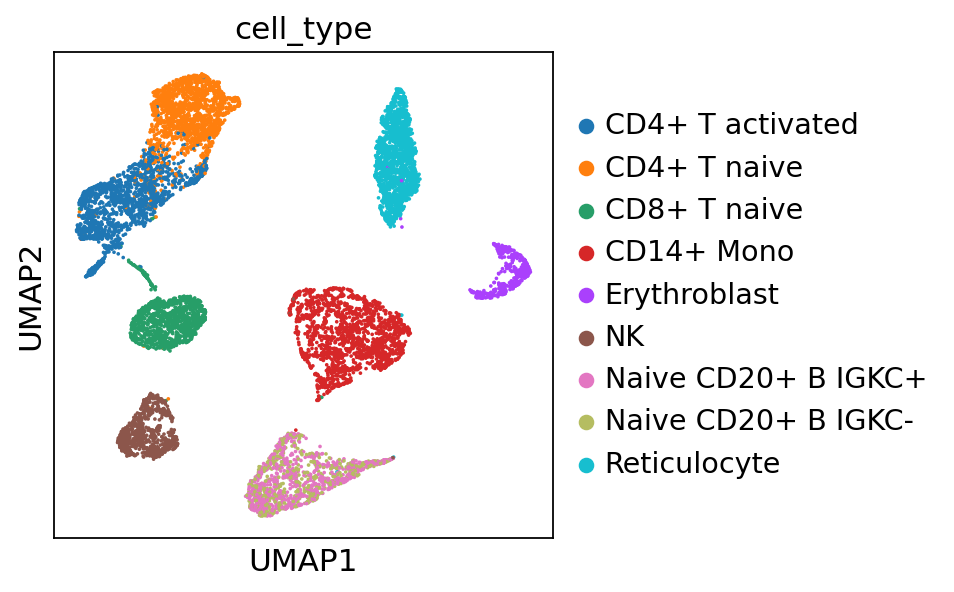

In [24]:
sc.set_figure_params(figsize=(4, 4))
emb = cell_emb_rna
obs = adata_rna.obs
EmbAdata = sc.AnnData(X=emb, obs=obs)
sc.pp.neighbors(EmbAdata)
sc.tl.umap(EmbAdata, min_dist=0.2, spread=1.0)
sc.pl.umap(EmbAdata, color=['cell_type'], ncols=2, wspace=0.3)
EmbAdata.write(save_path / "cell_emb.h5ad")

In [25]:
from scpmmi.utils.metrics import biology_conservation
metrics = {}
biology_conservation_metrics, best_res= biology_conservation(
    EmbAdata, EmbAdata.obs['cell_type'].values
)
metrics['AvgBIO'] = round(float(np.mean(list(biology_conservation_metrics.values()))), 3)
biology_conservation_metrics = {k: round(float(v), 3) for k, v in biology_conservation_metrics.items()}
metrics.update(biology_conservation_metrics)
metrics

{'AvgBIO': 0.886,
 'ARI': 0.916,
 'NMI': 0.941,
 'Mean average precision': 0.914,
 'ASW_celltype': 0.772}

In [26]:
from scpmmi.utils.metrics import batch_correct
if 'batch' in EmbAdata.obs.columns and len(set(EmbAdata.obs['batch'].unique())) > 1:
    batch_correct_metrics = batch_correct(
        EmbAdata, EmbAdata.obs['cell_type'].values, EmbAdata.obs['batch'].values
    )
    metrics['AvgBatch'] = round(float(np.mean(list(batch_correct_metrics.values()))), 3)
    batch_correct_metrics = {k: round(float(v), 3) for k, v in batch_correct_metrics.items()}
    metrics.update(batch_correct_metrics)
metrics

{'AvgBIO': 0.886,
 'ARI': 0.916,
 'NMI': 0.941,
 'Mean average precision': 0.914,
 'ASW_celltype': 0.772,
 'AvgBatch': 0.9,
 'Batch entropy mixing score': 0.851,
 'Seurat alignment score': 0.839,
 'Graph connectivity': 0.997,
 'bASW': 0.913}

In [27]:
if not os.path.exists(f'{save_path}/metrics.csv'):
    metrics_df = pd.DataFrame([metrics])
else:
    metrics_df = pd.read_csv(
        f'{save_path}/metrics.csv'
    )
    new_metrics_df = pd.DataFrame([metrics])
    metrics_df = pd.concat([metrics_df, new_metrics_df], ignore_index=True)
metrics_df.to_csv(f'{save_path}/metrics.csv', index=False)